# Silver layer — Steps 05, 06, 07, 09, 08

> **Development notebook.** The Silver layer is built and explained here. Once final, it is converted to the callable module `util/dataprocessing_silver.py`. Change this notebook first, then re-convert.

| Step | Section | Output (`datamart/silver/`) |
|---|---|---|
| 05 | Schema enforcement | `config/silver_schema.yaml` (schema contract), `_reports/schema_violations.csv`, `_reports/schema_drift.csv`, `_quarantine/<table>/` |
| 06 | Data validation | `_reports/validation_report.csv` (pre- and post-cleaning), `_reports/validation_failed_samples.csv` |
| 07 | Data cleaning | `<table>/snapshot_date=…/*.parquet`, `_reports/cleaning_audit.csv`, `_silver_log.csv` |
| 09 | Reusable transforms | Parsed columns in Silver (`credit_history_age_months`, `type_of_loan_list`, `num_loan_types`), unit tests |
| — | Decision register | `_reports/silver_decisions.csv`: every Bronze finding (step 04) → decision → verification |
| 08 | Post-cleaning EDA | `_eda/bronze_vs_silver_comparison.csv`, `_eda/silver_vs_bronze_action_log.csv`, `_eda/silver_profile_baseline.csv`, `_eda/charts/` |

**Order:** 05 → 06 (before cleaning: what is wrong) → 07 → 09 → 06 again (after cleaning: the acceptance check) → write Parquet. Step 08 (post-cleaning EDA) runs last, on the finished Silver.

**Decisions agreed for this layer**

| Finding | Decision |
|---|---|
| Out-of-range numeric values (Age −500 / 8,678, 1,756 bank accounts, …) | **Null + `<column>_invalid` flag.** Row kept; imputation happens later, fitted on training data only (step 18). |
| Trailing underscores (`32_`, `52312.68_`) | **Correct:** strip and cast. |
| Placeholder tokens (`_______`, `_`, `!@9#%8`, `__10000__`, `__-333…__`) | **Null + flag.** |
| `NM` in Payment_of_Min_Amount | **Null + flag** (NM customers look like a mix of Yes and No, i.e. not recorded). |
| Empty `Type_of_Loan` | **Means "no loans"** (1,363 of 1,426 empty rows have Num_of_Loan = 0) → empty list, count 0. |
| Negative `Delay_from_due_date` (−5 … −1) | **Accept** (paid before the due date). |
| `Total_EMI_per_month` > `Monthly_Inhand_Salary` (236 rows, found by the step-08 overlay) | **Null + flag** (cross-field rule: an instalment cannot exceed take-home pay). |
| `Name`, `SSN` | **Not loaded** into Silver (PII). |
| Critical fields (keys, dates, loan ledger) | Null or invalid → **quarantine the row**; never imputed. |
| `Credit_History_Age`, `Type_of_Loan` text | **Parse (step 09)** into months / list + count; original text kept for audit. |

In [1]:
import os, sys, shutil, time, uuid
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
from pyspark.sql import Window, functions as F, types as T

# Project folder: /app inside the Docker container, otherwise the parent of this notebook's folder
PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze      # Bronze reader, contract and profiling rules (reused)

SILVER_DIR     = os.path.join(PROJECT_DIR, "datamart", "silver")
REPORT_DIR     = os.path.join(SILVER_DIR, "_reports")
QUARANTINE_DIR = os.path.join(SILVER_DIR, "_quarantine")
LOG_PATH       = os.path.join(SILVER_DIR, "_silver_log.csv")
for d in (SILVER_DIR, REPORT_DIR, QUARANTINE_DIR):
    os.makedirs(d, exist_ok=True)

with open(os.path.join(PROJECT_DIR, "config", "silver_schema.yaml"), encoding="utf-8") as f:
    SCHEMA = yaml.safe_load(f)
TABLES = list(SCHEMA["tables"])

spark = bronze.get_spark("silver")

## Configuration

In [2]:
# Plausible ranges: Bronze profiling rules, with Silver overrides
SILVER_RANGE_RULES = {
    **bronze.RANGE_RULES,
    ("features_financials", "Delay_from_due_date"):      (-30, 365),   # negative = paid early (accepted)
    ("features_financials", "Credit_Utilization_Ratio"): (0, 100),
}

# Allowed values of categorical columns (anything else is a validation failure)
VALID_CATEGORIES = {
    ("features_attributes", "Occupation"): [
        "Accountant", "Architect", "Developer", "Doctor", "Engineer", "Entrepreneur", "Journalist", "Lawyer",
        "Manager", "Mechanic", "Media_Manager", "Musician", "Scientist", "Teacher", "Writer"],
    ("features_financials", "Credit_Mix"): ["Good", "Standard", "Bad"],
    ("features_financials", "Payment_of_Min_Amount"): ["Yes", "No"],
    ("features_financials", "Payment_Behaviour"): [
        "High_spent_Large_value_payments", "High_spent_Medium_value_payments", "High_spent_Small_value_payments",
        "Low_spent_Large_value_payments", "Low_spent_Medium_value_payments", "Low_spent_Small_value_payments"],
}

# Formats that must hold in Silver
SILVER_FORMAT_RULES = {
    ("lms_loan_daily", "loan_id"): r"CUS_0x[0-9a-f]+_\d{4}_\d{2}_\d{2}",
    **{(t, "Customer_ID"): r"CUS_0x[0-9a-f]+" for t in TABLES},
    ("features_financials", "Credit_History_Age"): r"\d+ Years? and \d+ Months?",
}

# Columns that get a <column>_invalid flag when cleaning sets an unusable value to null
CLEANING_FLAG_COLUMNS = {
    "features_attributes": ["Age", "Occupation"],
    "features_financials": ["Annual_Income", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan",
                            "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries", "Credit_Mix",
                            "Payment_of_Min_Amount", "Total_EMI_per_month", "Amount_invested_monthly",
                            "Payment_Behaviour", "Monthly_Balance"],
}

# Cross-field rules applied after the column-level cleaning: (table, target column, condition, audit action).
# Where the condition is true the target is impossible given another field -> null + <target>_invalid flag.
CROSS_FIELD_NULL_RULES = [
    ("features_financials", "Total_EMI_per_month",
     lambda: F.col("Total_EMI_per_month") > F.col("Monthly_Inhand_Salary"),   # instalment > take-home pay
     "exceeds_monthly_salary_to_null"),
]

KNOWN_LOAN_TYPES = ["Auto Loan", "Credit-Builder Loan", "Debt Consolidation Loan", "Home Equity Loan",
                    "Mortgage Loan", "Not Specified", "Payday Loan", "Personal Loan", "Student Loan"]

DATA_START = "2023-01-01"           # earliest valid snapshot_date
NULL_PCT_DEFAULT  = (5, 30)         # null % thresholds (warn, fail) for feature columns
NULL_PCT_CRITICAL = (0, 0)

## Helpers

- `safe_cast` — strict cast: a value becomes a number/date only if it fully matches the expected format; otherwise null. Nothing is guessed (e.g. `NaN`, `1,000` or `12_` never silently become numbers).
- `clean_numeric_col` / `clean_category_col` — the step-07 cleaning rules for one column, returning the cleaned value plus the reason flags used by the cleaning audit.
- `credit_history_months` / `loan_type_list` — the step-09 parsers (also used by a step-06 cross-field rule). All are built from Spark built-in functions (no Python UDFs).

In [3]:
NUM_RX  = f"^{bronze.NUMERIC_RE}$"
DATE_RX = f"^{bronze.DATE_RE}$"
TRAILING_UNDERSCORE_RX = r"^([+-]?(\d+(\.\d*)?|\.\d+))_+$"
PLACEHOLDER_RX = f"^(?:{bronze.PLACEHOLDER_RE})$"
CHA_RX = r"^\s*(\d+)\s+Years?\s+and\s+(\d+)\s+Months?\s*$"


def _col(c):
    return F.col(c) if isinstance(c, str) else c


def safe_cast(c, typ):
    c = _col(c)
    if typ == "string":
        return c
    if typ == "date":
        return F.when(c.rlike(DATE_RX), F.to_date(c, "yyyy-MM-dd"))
    num = F.when(c.rlike(NUM_RX), c.cast("double"))
    if typ == "double":
        return num
    if typ == "int":
        return F.when((num == F.floor(num)) & num.between(-2147483648, 2147483647), num.cast("long")).cast("int")
    raise ValueError(f"unknown type {typ}")


def clean_numeric_col(c, typ, rng=None):
    raw = F.trim(F.col(c))
    stripped = F.regexp_replace(raw, TRAILING_UNDERSCORE_RX, "$1")      # '32_' -> '32'
    cast = safe_cast(stripped, typ)
    token = raw.isNotNull() & cast.isNull()                              # '_', '__10000__', ...
    if rng:
        lo, hi = rng
        out_of_range = cast.isNotNull() & ((cast < lo) | (cast > hi))
    else:
        out_of_range = F.lit(False)
    return dict(value=F.when(~out_of_range, cast),
                underscore=raw.isNotNull() & (stripped != raw) & cast.isNotNull(),
                token=token, out_of_range=out_of_range, invalid=token | out_of_range)


def clean_category_col(c, codes=()):
    raw = F.trim(F.col(c))
    placeholder = raw.isNotNull() & (raw.rlike(PLACEHOLDER_RX) | raw.isin(list(codes)))
    return dict(value=F.when(~placeholder, raw), placeholder=placeholder, invalid=placeholder)


def credit_history_months(c):
    c = F.trim(_col(c))
    years, months = F.regexp_extract(c, CHA_RX, 1), F.regexp_extract(c, CHA_RX, 2)
    ok = c.rlike(CHA_RX) & (months.cast("int") < 12)
    return F.when(ok, years.cast("int") * 12 + months.cast("int"))


def loan_type_list(c):
    c = F.trim(_col(c))
    norm = F.regexp_replace(c, r",\s*and\s+", ", ")          # 'A, B, and C' -> 'A, B, C'
    norm = F.regexp_replace(norm, r"\s+and\s+", ", ")        # 'A and B'     -> 'A, B'
    parts = F.transform(F.split(norm, ","), lambda x: F.trim(x))
    return F.when(c.isNull() | (c == ""), F.array().cast("array<string>")).otherwise(
        F.filter(parts, lambda x: x != ""))

---

## Step 05 — Schema enforcement

The schema contract `config/silver_schema.yaml` defines every column's type, whether it is **required** (must exist in Bronze) and whether it is **critical** (keys, dates, loan-ledger amounts used for the label).

| Situation | Policy |
|---|---|
| Required column missing from Bronze | **FAIL** — stop the build |
| Optional column missing | WARN — add as null |
| Unexpected extra column | WARN — dropped from Silver |
| PII column (`Name`, `SSN`) | Not loaded into Silver |
| Critical value null or not castable | **Quarantine the row** (with the reason) |
| Non-critical value not castable (e.g. `32_`, `_`) | Recorded as a violation; raw value passed to step 07, which corrects it or sets it to null |

In [4]:
def check_drift(table, df, schema=SCHEMA):
    spec = schema["tables"][table]["columns"]
    findings = []
    missing_req = [c for c, s in spec.items() if s.get("required") and c not in df.columns]
    if missing_req:
        raise ValueError(f"{table}: required columns missing from Bronze: {missing_req}")
    for c, s in spec.items():
        if not s.get("required") and c not in df.columns:
            df = df.withColumn(c, F.lit(None).cast("string"))
            findings.append(dict(table=table, column=c, finding="optional column missing", status="WARN",
                                 action="added as null"))
    for c in df.columns:
        if c not in spec and not c.startswith("_"):
            findings.append(dict(table=table, column=c, finding="unexpected column", status="WARN",
                                 action="dropped from Silver"))
    return df, findings


def enforce_schema(table, df, schema=SCHEMA):
    spec = schema["tables"][table]["columns"]
    df, drift = check_drift(table, df, schema)
    for c, s in spec.items():
        if s.get("pii"):
            drift.append(dict(table=table, column=c, finding="PII column", status="INFO", action="not loaded"))
    keep = [c for c, s in spec.items() if not s.get("pii")]
    df = df.select(*keep, *schema["lineage_columns"])

    reasons, stats = [], []
    for c in keep:
        s = spec[c]
        bad_cast = F.col(c).isNotNull() & safe_cast(c, s["type"]).isNull()
        stats += [F.sum(F.col(c).isNull().cast("int")).alias(f"{c}|nulls"),
                  F.sum(bad_cast.cast("int")).alias(f"{c}|cast_failures")]
        if s.get("critical"):
            reasons.append(F.when(F.col(c).isNull(), F.lit(f"{c}: null"))
                            .when(bad_cast, F.concat(F.lit(f"{c}: not a valid {s['type']} '"), F.col(c), F.lit("'"))))
    df = df.withColumn("_quarantine_reason", F.concat_ws("; ", *reasons) if reasons else F.lit(""))

    agg = df.agg(F.count("*").alias("rows"), *stats).first().asDict()
    violations = []
    for c in keep:
        s, nulls, fails = spec[c], agg[f"{c}|nulls"], agg[f"{c}|cast_failures"]
        if nulls or fails:
            examples = ""
            if fails:
                ex = (df.filter(F.col(c).isNotNull() & safe_cast(c, s["type"]).isNull())
                        .groupBy(c).count().orderBy(F.desc("count")).limit(5).collect())
                examples = "; ".join(f"{r[c]} ({r['count']:,})" for r in ex)
            violations.append(dict(
                table=table, column=c, type=s["type"], critical=bool(s.get("critical")),
                nulls=nulls, cast_failures=fails, pct=(nulls + fails) / agg["rows"] * 100, examples=examples,
                action="quarantine row" if s.get("critical") else "pass raw value to cleaning (step 07)"))

    passed = df.filter(F.col("_quarantine_reason") == "").drop("_quarantine_reason")
    quarantined = df.filter(F.col("_quarantine_reason") != "")
    return passed, quarantined, violations, drift

### Step 05 tests — edge cases

In [5]:
TEST_SCHEMA = {
    "lineage_columns": ["_source_file", "_source_row_num", "_batch_id"],
    "tables": {"t": {"keys": ["id"], "columns": {
        "id":     {"type": "string", "required": True, "critical": True},
        "d":      {"type": "date",   "required": True, "critical": True},
        "n":      {"type": "int",    "required": True},
        "x":      {"type": "double", "required": True},
        "opt":    {"type": "string", "required": False},
        "secret": {"type": "string", "required": False, "pii": True}}}}}

rows = [("A",  "2024-01-01", "12",   "1.5",  "s1", "f", "1", "b"),   # valid
        ("B",  "2024-13-01", "12.0", "2",    "s2", "f", "2", "b"),   # impossible date (critical) -> quarantine
        (None, "2024-01-01", "12_",  "1e3",  "s3", "f", "3", "b"),   # null key (critical) -> quarantine
        ("C",  "2024-02-01", "12.5", "NaN",  "s4", "f", "4", "b"),   # non-integer int, 'NaN' double -> violations, kept
        ("D",  "2024-02-01", "1,000", "_",   "s5", "f", "5", "b")]   # '1,000' and '_' -> violations, kept
cols = ["id", "d", "n", "x", "secret", "_source_file", "_source_row_num", "_batch_id"]
test_df = spark.createDataFrame(rows, cols).withColumn("unexpected", F.lit("z"))

p, q, v, drift = enforce_schema("t", test_df, TEST_SCHEMA)
assert sorted(r["id"] for r in p.collect()) == ["A", "C", "D"], "wrong rows passed"
assert sorted(r["_quarantine_reason"] for r in q.collect()) == ["d: not a valid date '2024-13-01'", "id: null"]
assert "secret" not in p.columns and "unexpected" not in p.columns and "opt" in p.columns
viol = {r["column"]: r for r in v}
# violations are counted over all rows, including quarantined ones: n -> '12_', '12.5', '1,000'; x -> 'NaN', '_'
assert viol["n"]["cast_failures"] == 3 and viol["x"]["cast_failures"] == 2, viol
assert {(d["column"], d["finding"]) for d in drift} >= {("opt", "optional column missing"),
                                                         ("unexpected", "unexpected column"), ("secret", "PII column")}
try:
    enforce_schema("t", test_df.drop("n"), TEST_SCHEMA)
    raise AssertionError("missing required column was not rejected")
except ValueError as e:
    assert "required columns missing" in str(e)
print("Step 05 tests passed: valid rows kept, critical failures quarantined, non-critical violations passed on, "
      "PII/extra columns dropped, optional column added, missing required column rejected")

Step 05 tests passed: valid rows kept, critical failures quarantined, non-critical violations passed on, PII/extra columns dropped, optional column added, missing required column rejected


### Run step 05

In [6]:
bronze_frames, passed, quarantined = {}, {}, {}
all_violations, all_drift = [], []
for t in TABLES:
    bronze_frames[t] = bronze.read_bronze(spark, t).cache()
    p, q, v, d = enforce_schema(t, bronze_frames[t])
    passed[t], quarantined[t] = p.cache(), q.cache()
    all_violations += v
    all_drift += d

schema_violations = pd.DataFrame(all_violations)
schema_drift = pd.DataFrame(all_drift)
schema_violations.to_csv(os.path.join(REPORT_DIR, "schema_violations.csv"), index=False)
schema_drift.to_csv(os.path.join(REPORT_DIR, "schema_drift.csv"), index=False)

summary_05 = pd.DataFrame([dict(table=t, bronze_rows=bronze_frames[t].count(), passed=passed[t].count(),
                                quarantined=quarantined[t].count()) for t in TABLES])
display(summary_05.style.hide(axis="index").format({"bronze_rows": "{:,}", "passed": "{:,}", "quarantined": "{:,}"}))
display(schema_drift.style.hide(axis="index"))
schema_violations.style.hide(axis="index").format({"pct": "{:.2f}%", "nulls": "{:,}", "cast_failures": "{:,}"})

table,bronze_rows,passed,quarantined
lms_loan_daily,"137,500","137,500",0
feature_clickstream,"215,376","215,376",0
features_attributes,"12,500","12,500",0
features_financials,"12,500","12,500",0


table,column,finding,status,action
features_attributes,Name,PII column,INFO,not loaded
features_attributes,SSN,PII column,INFO,not loaded


table,column,type,critical,nulls,cast_failures,pct,examples,action
features_attributes,Age,int,False,0,637,5.10%,39_ (25); 32_ (25); 24_ (23); 29_ (23); 21_ (23),pass raw value to cleaning (step 07)
features_financials,Annual_Income,double,False,0,859,6.87%,17887.47_ (1); 19604.35_ (1); 8749.465_ (1); 33410.45_ (1); 36984.76_ (1),pass raw value to cleaning (step 07)
features_financials,Num_of_Loan,int,False,0,623,4.98%,2_ (110); 4_ (105); 3_ (79); 0_ (76); 1_ (64),pass raw value to cleaning (step 07)
features_financials,Type_of_Loan,string,False,"1,426",0,11.41%,,pass raw value to cleaning (step 07)
features_financials,Num_of_Delayed_Payment,int,False,0,374,2.99%,18_ (25); 19_ (24); 12_ (23); 20_ (23); 15_ (23),pass raw value to cleaning (step 07)
features_financials,Changed_Credit_Limit,double,False,0,254,2.03%,_ (254),pass raw value to cleaning (step 07)
features_financials,Outstanding_Debt,double,False,0,139,1.11%,270.42_ (1); 127.88_ (1); 135.37_ (1); 384.22_ (1); 758.45_ (1),pass raw value to cleaning (step 07)
features_financials,Amount_invested_monthly,double,False,0,558,4.46%,__10000__ (558),pass raw value to cleaning (step 07)
features_financials,Monthly_Balance,double,False,0,1,0.01%,__-333333333333333333333333333__ (1),pass raw value to cleaning (step 07)


---

## Step 06 — Data validation

A configurable rule set, run **twice**: on the type-cast data **before cleaning** (what is wrong) and on the finished Silver **after cleaning** (the acceptance check: no FAIL allowed). Each rule has a severity expressed as thresholds on the % of rows violating it: **WARN** above `warn_pct`, **FAIL** above `fail_pct`.

| Kind | Rules | warn / fail % |
|---|---|---|
| Keys | not null, unique per table key | 0 / 0 |
| NULL % | every non-key column | 5 / 30 (critical columns 0 / 0) |
| Ranges | plausible ranges (Bronze rules + Silver overrides) | 0 / 1 |
| Categories | allowed values of Occupation, Credit_Mix, Payment_of_Min_Amount, Payment_Behaviour | 0 / 1 |
| Formats | Customer_ID, loan_id, Credit_History_Age | 0 / 0 |
| Dates | snapshot within the data window; loan snapshot ≥ loan start; MOB = months since start | 0 / 0 |
| Cross-field | loan ledger (balance, overdue reconcile with payments); Num_of_Loan = entries in Type_of_Loan; salary vs income | ledger 0 / 0, others small |
| Foreign keys | feature customers exist in the loan table; every loan customer has attributes and financials | 0 / 0 |
| Coverage | loan customers with clickstream history (BRZ-001, accepted) | 0 / 50 |

In [7]:
# A rule is either a row-level expression ("expr": evaluated for all such rules of a table in ONE Spark pass)
# or a function that needs a window / join ("check": returns the frame with a boolean _viol column).
def viol(expr):
    return dict(expr=expr)


def unique_check(keys):
    return dict(check=lambda df, frames: df.withColumn("_viol", F.count("*").over(Window.partitionBy(*keys)) > 1))


def ledger_check(target):
    def fn(df, frames):
        w = Window.partitionBy("loan_id").orderBy("installment_num").rowsBetween(Window.unboundedPreceding, 0)
        d = df.withColumn("_cum_paid", F.sum("paid_amt").over(w)).withColumn("_cum_due", F.sum("due_amt").over(w))
        expected = (F.col("loan_amt") - F.col("_cum_paid")) if target == "balance" else (F.col("_cum_due") - F.col("_cum_paid"))
        return d.withColumn("_viol", F.abs(F.col(target) - expected) > 0.01)
    return dict(check=fn)


def fk_check(col, parent, parent_col):
    def fn(df, frames):
        keys = frames[parent].select(F.col(parent_col).alias("_fk_key")).distinct()
        return (df.join(keys, F.col(col) == F.col("_fk_key"), "left")
                  .withColumn("_viol", F.col("_fk_key").isNull() & F.col(col).isNotNull()))
    return dict(check=fn)


def build_rules(frames):
    as_of = frames["lms_loan_daily"].agg(F.max("snapshot_date")).first()[0]
    rules = []

    def add(table, rule, kind, columns, test, warn, fail):
        rules.append(dict(rule_id=f"V{len(rules) + 1:03d}", table=table, rule=rule, kind=kind,
                          columns=columns, warn_pct=warn, fail_pct=fail, **test))

    for t, tspec in SCHEMA["tables"].items():
        keys = tspec["keys"]
        for k in keys:
            add(t, f"{k} not null", "key", [k], viol(F.col(k).isNull()), 0, 0)
        add(t, f"one row per {' + '.join(keys)}", "key", keys, unique_check(keys), 0, 0)
        for c, s in tspec["columns"].items():
            if s.get("pii") or c in keys:
                continue
            add(t, f"{c} null %", "null_pct", [c], viol(F.col(c).isNull()),
                *(NULL_PCT_CRITICAL if s.get("critical") else NULL_PCT_DEFAULT))
        add(t, f"snapshot_date in [{DATA_START}, {as_of}]", "date", ["snapshot_date"],
            viol((F.col("snapshot_date") < F.lit(DATA_START).cast("date")) | (F.col("snapshot_date") > F.lit(as_of))), 0, 0)

    for (t, c), (lo, hi) in SILVER_RANGE_RULES.items():
        add(t, f"{c} in [{lo:,}, {hi:,}]", "range", [c],
            viol(F.col(c).isNotNull() & ((F.col(c) < lo) | (F.col(c) > hi))), 0, 1)
    for (t, c), values in VALID_CATEGORIES.items():
        add(t, f"{c} in allowed set", "category", [c], viol(F.col(c).isNotNull() & ~F.col(c).isin(values)), 0, 1)
    for (t, c), rx in SILVER_FORMAT_RULES.items():
        add(t, f"{c} format", "format", [c], viol(F.col(c).isNotNull() & ~F.col(c).rlike(f"^{rx}$")), 0, 0)

    lms = "lms_loan_daily"
    add(lms, "snapshot_date >= loan_start_date", "date", ["snapshot_date", "loan_start_date"],
        viol(F.col("snapshot_date") < F.col("loan_start_date")), 0, 0)
    add(lms, "installment_num = months since loan_start_date", "cross_field", ["installment_num"],
        viol(F.months_between("snapshot_date", "loan_start_date") != F.col("installment_num")), 0, 0)
    add(lms, "balance = loan_amt - cumulative paid_amt", "cross_field", ["balance"], ledger_check("balance"), 0, 0)
    add(lms, "overdue_amt = cumulative due_amt - cumulative paid_amt", "cross_field", ["overdue_amt"],
        ledger_check("overdue_amt"), 0, 0)

    fin = "features_financials"
    add(fin, "Num_of_Loan = number of entries in Type_of_Loan", "cross_field", ["Num_of_Loan", "Type_of_Loan"],
        viol(F.col("Num_of_Loan").isNotNull() & (F.col("Num_of_Loan") != F.size(loan_type_list("Type_of_Loan")))),
        0.1, 1)
    add(fin, "Total_EMI_per_month <= Monthly_Inhand_Salary", "cross_field", ["Total_EMI_per_month", "Monthly_Inhand_Salary"],
        viol(F.col("Total_EMI_per_month") > F.col("Monthly_Inhand_Salary")), 0, 1)
    ratio = F.col("Monthly_Inhand_Salary") * 12 / F.col("Annual_Income")
    add(fin, "12 x Monthly_Inhand_Salary / Annual_Income in [0.05, 1.5]", "cross_field",
        ["Monthly_Inhand_Salary", "Annual_Income"], viol(ratio.isNotNull() & ~ratio.between(0.05, 1.5)), 0.5, 2)

    for t in ["feature_clickstream", "features_attributes", "features_financials"]:
        add(t, "Customer_ID exists in lms_loan_daily", "foreign_key", ["Customer_ID"],
            fk_check("Customer_ID", lms, "Customer_ID"), 0, 0)
    for t in ["features_attributes", "features_financials"]:
        add(lms, f"loan customer has a row in {t}", "foreign_key", ["Customer_ID"],
            fk_check("Customer_ID", t, "Customer_ID"), 0, 0)
    add(lms, "loan customer has clickstream history (BRZ-001, accepted)", "coverage", ["Customer_ID"],
        fk_check("Customer_ID", "feature_clickstream", "Customer_ID"), 0, 50)
    return rules


def violating_rows(r, frames):
    df = frames[r["table"]]
    if "expr" in r:
        return df.filter(F.coalesce(r["expr"], F.lit(False)))
    return r["check"](df, frames).filter(F.col("_viol"))


def run_rules(frames, rules, stage):
    totals = {t: df.count() for t, df in frames.items()}
    counts = {}
    for t, df in frames.items():                      # all row-level rules of a table in one pass
        simple = [r for r in rules if r["table"] == t and "expr" in r]
        if simple:
            counts.update(df.agg(*[F.sum(F.coalesce(r["expr"], F.lit(False)).cast("int")).alias(r["rule_id"])
                                   for r in simple]).first().asDict())
    for r in rules:                                   # window / join rules one by one
        if "check" in r:
            counts[r["rule_id"]] = violating_rows(r, frames).count()

    report, samples = [], []
    for r in rules:
        n = counts[r["rule_id"]] or 0
        pct = n / totals[r["table"]] * 100
        status = "FAIL" if pct > r["fail_pct"] else "WARN" if pct > r["warn_pct"] else "PASS"
        report.append(dict(stage=stage, rule_id=r["rule_id"], table=r["table"], kind=r["kind"], rule=r["rule"],
                           violations=n, pct=round(pct, 3), warn_pct=r["warn_pct"], fail_pct=r["fail_pct"],
                           status=status))
        if n:
            keys = SCHEMA["tables"][r["table"]]["keys"]
            show = list(dict.fromkeys(keys + r["columns"]))
            for row in violating_rows(r, frames).select(*show).limit(5).collect():
                samples.append(dict(stage=stage, rule_id=r["rule_id"], table=r["table"], rule=r["rule"],
                                    sample=str({k: str(row[k]) for k in show})))
    return pd.DataFrame(report), pd.DataFrame(samples)


STATUS_STYLE = {"PASS": ("✔ PASS", "#e3f4e3"), "WARN": ("▲ WARN", "#fdf0d2"), "FAIL": ("✖ FAIL", "#f8dede")}

def styled(df, cols=("status",)):
    view = df.copy()
    for c in cols:
        view[c] = view[c].map(lambda s: STATUS_STYLE.get(s, (s,))[0])
    return view.style.apply(
        lambda col: [f"background-color: {STATUS_STYLE[v.split()[-1]][1]}" if isinstance(v, str)
                     and v.split()[-1] in STATUS_STYLE else "" for v in col], subset=list(cols)).hide(axis="index")

### Run step 06 — before cleaning

In [8]:
def cast_all(table, df):
    # Type-cast view of the passed rows, no cleaning: shows what validation finds in the raw values
    spec = SCHEMA["tables"][table]["columns"]
    return df.select(*[safe_cast(c, s["type"]).alias(c) for c, s in spec.items() if not s.get("pii")],
                     *SCHEMA["lineage_columns"])

typed_pre = {t: cast_all(t, passed[t]).cache() for t in TABLES}
rules_pre = build_rules(typed_pre)
validation_pre, samples_pre = run_rules(typed_pre, rules_pre, "pre_clean")
print("Before cleaning:", validation_pre["status"].value_counts().to_dict())
styled(validation_pre[validation_pre["status"] != "PASS"].drop(columns="stage"))

Before cleaning: {'PASS': 83, 'FAIL': 14, 'WARN': 6}


rule_id,table,kind,rule,violations,pct,warn_pct,fail_pct,status
V041,features_attributes,null_pct,Age null %,637,5.096000,5.000000,30,▲ WARN
V047,features_financials,null_pct,Annual_Income null %,859,6.872000,5.000000,30,▲ WARN
V053,features_financials,null_pct,Type_of_Loan null %,1426,11.408000,5.000000,30,▲ WARN
V068,features_attributes,range,"Age in [14, 100]",306,2.448000,0.000000,1,✖ FAIL
V069,features_financials,range,"Annual_Income in [0, 1,000,000]",105,0.840000,0.000000,1,▲ WARN
V070,features_financials,range,"Num_Bank_Accounts in [0, 50]",168,1.344000,0.000000,1,✖ FAIL
V071,features_financials,range,"Num_Credit_Card in [0, 50]",289,2.312000,0.000000,1,✖ FAIL
V072,features_financials,range,"Interest_Rate in [0, 100]",268,2.144000,0.000000,1,✖ FAIL
V073,features_financials,range,"Num_of_Loan in [0, 50]",560,4.480000,0.000000,1,✖ FAIL
V075,features_financials,range,"Num_of_Delayed_Payment in [0, 365]",178,1.424000,0.000000,1,✖ FAIL


---

## Step 07 — Data cleaning

Applied column by column according to the schema and the agreed decisions:

| Column type | Cleaning |
|---|---|
| Numeric | trim → strip trailing underscores (`32_` → `32`) → strict cast → invalid token → **null** → outside plausible range → **null**; `<column>_invalid` flag set when a value was nulled |
| Categorical | trim → placeholder (`_______`, `_`, `!@9#%8`) or unclear code (`NM`) → **null** + flag |
| Date | strict `yyyy-MM-dd` cast |
| IDs / text | trim; never modified otherwise (critical IDs are never imputed — invalid ones were quarantined in step 05) |
| Cross-field | after the column rules: `Total_EMI_per_month` > `Monthly_Inhand_Salary` → **null** + flag |
| Duplicates | one row per table key; priority: latest Bronze batch, then last row in the source file |

Every action is counted in the cleaning audit, with before/after row counts per table.

In [9]:
def clean_table(table, df):
    tspec = SCHEMA["tables"][table]
    flags_for = set(CLEANING_FLAG_COLUMNS.get(table, []))
    select, audit = [], {}
    for c, s in tspec["columns"].items():
        if s.get("pii"):
            continue
        invalid = None
        if s["type"] in ("int", "double"):
            r = clean_numeric_col(c, s["type"], SILVER_RANGE_RULES.get((table, c)))
            value, invalid = r["value"], r["invalid"]
            audit[(c, "trailing_underscore_corrected")] = r["underscore"]
            audit[(c, "invalid_token_to_null")] = r["token"]
            audit[(c, "out_of_range_to_null")] = r["out_of_range"]
        elif s["type"] == "date":
            value = safe_cast(F.trim(F.col(c)), "date")
            audit[(c, "invalid_date_to_null")] = F.col(c).isNotNull() & value.isNull()
        elif (table, c) in VALID_CATEGORIES:
            r = clean_category_col(c, bronze.KNOWN_CODES.get((table, c), []))
            value, invalid = r["value"], r["placeholder"]
            audit[(c, "placeholder_to_null")] = r["placeholder"]
        else:
            value = F.trim(F.col(c))
            audit[(c, "whitespace_trimmed")] = F.col(c) != value
        select.append(value.alias(c))
        if c in flags_for:
            select.append(F.coalesce(invalid, F.lit(False)).alias(f"{c}_invalid"))

    counts = df.agg(*[F.sum(e.cast("int")).alias(f"{c}|{a}") for (c, a), e in audit.items()]).first().asDict()
    rows_in = df.count()
    audit_rows = [dict(table=table, column=k.split("|")[0], action=k.split("|")[1], rows_affected=v or 0,
                       pct=(v or 0) / rows_in * 100) for k, v in counts.items() if v]

    cleaned = df.select(*select, F.col("_source_file"), F.col("_source_row_num").cast("long"),
                        F.col("_batch_id").alias("_bronze_batch_id"))

    # Cross-field rules on the cleaned values (flag first, then null the target)
    for t, target, condition, action in CROSS_FIELD_NULL_RULES:
        if t != table:
            continue
        cond = F.coalesce(condition(), F.lit(False))
        n = cleaned.filter(cond).count()
        if n:
            audit_rows.append(dict(table=table, column=target, action=action, rows_affected=n, pct=n / rows_in * 100))
        cleaned = (cleaned.withColumn(f"{target}_invalid", F.col(f"{target}_invalid") | cond)
                          .withColumn(target, F.when(~cond, F.col(target))))

    # Deduplicate by key: keep the latest Bronze batch, then the last row in the source file
    w = Window.partitionBy(*tspec["keys"]).orderBy(F.desc("_bronze_batch_id"), F.desc("_source_row_num"))
    deduped = cleaned.withColumn("_rank", F.row_number().over(w)).filter("_rank = 1").drop("_rank")
    return deduped, audit_rows, rows_in

### Step 07 tests — cleaning rules on known values

In [10]:
def apply(fn_result, values, typ=T.StringType()):
    df = spark.createDataFrame([(v,) for v in values], T.StructType([T.StructField("v", typ)]))
    return [tuple(r) for r in df.select(fn_result["value"].alias("value"), fn_result["invalid"].alias("invalid")).collect()]

# Numeric: Age-like column, plausible range [14, 100]
got = apply(clean_numeric_col("v", "int", (14, 100)), ["32", "32_", "-500", "8678", "_", "__10000__", " 45 ", None])
assert got == [(32, False), (32, False), (None, True), (None, True), (None, True), (None, True), (45, False),
               (None, False)], got

# Numeric double with sentinel tokens
got = apply(clean_numeric_col("v", "double"), ["52312.68_", "__-333333333333333333333333333__", "_", "1.5"])
assert got == [(52312.68, False), (None, True), (None, True), (1.5, False)], got

# Categorical: placeholders and unclear codes
got = apply(clean_category_col("v", ["NM"]), ["Lawyer", "_______", "_", "!@9#%8", "NM", "Yes", None])
assert got == [("Lawyer", False), (None, True), (None, True), (None, True), (None, True), ("Yes", False),
               (None, False)], got
print("Step 07 tests passed: underscores corrected, tokens and out-of-range values nulled + flagged, "
      "valid values and genuine nulls untouched")

Step 07 tests passed: underscores corrected, tokens and out-of-range values nulled + flagged, valid values and genuine nulls untouched


### Run step 07

In [11]:
cleaned, cleaning_audit, table_log = {}, [], []
for t in TABLES:
    df, audit_rows, rows_in = clean_table(t, passed[t])
    cleaned[t] = df.cache()
    cleaning_audit += audit_rows
    table_log.append(dict(table=t, bronze_rows=bronze_frames[t].count(), quarantined=quarantined[t].count(),
                          rows_into_cleaning=rows_in, duplicates_removed=rows_in - cleaned[t].count(),
                          silver_rows=cleaned[t].count()))

cleaning_audit = pd.DataFrame(cleaning_audit)
before_after = pd.DataFrame(table_log)
display(before_after.style.hide(axis="index").format({c: "{:,}" for c in before_after.columns if c != "table"}))
cleaning_audit.style.hide(axis="index").format({"rows_affected": "{:,}", "pct": "{:.2f}%"})

table,bronze_rows,quarantined,rows_into_cleaning,duplicates_removed,silver_rows
lms_loan_daily,"137,500",0,"137,500",0,"137,500"
feature_clickstream,"215,376",0,"215,376",0,"215,376"
features_attributes,"12,500",0,"12,500",0,"12,500"
features_financials,"12,500",0,"12,500",0,"12,500"


table,column,action,rows_affected,pct
features_attributes,Age,trailing_underscore_corrected,637,5.10%
features_attributes,Age,out_of_range_to_null,319,2.55%
features_attributes,Occupation,placeholder_to_null,880,7.04%
features_financials,Annual_Income,trailing_underscore_corrected,859,6.87%
features_financials,Annual_Income,out_of_range_to_null,110,0.88%
features_financials,Num_Bank_Accounts,out_of_range_to_null,168,1.34%
features_financials,Num_Credit_Card,out_of_range_to_null,289,2.31%
features_financials,Interest_Rate,out_of_range_to_null,268,2.14%
features_financials,Num_of_Loan,trailing_underscore_corrected,623,4.98%
features_financials,Num_of_Loan,out_of_range_to_null,563,4.50%


---

## Step 09 — Reusable transforms

Deterministic, row-level parsing (no fitting on data, so no leakage risk before the train/test split). The original text columns are kept for audit.

| New column | From | Rule |
|---|---|---|
| `credit_history_age_months` | `Credit_History_Age` | `'16 Years and 3 Months'` → 16 × 12 + 3 = 195; unknown format or months ≥ 12 → null |
| `type_of_loan_list` | `Type_of_Loan` | `'A, B, and C'` / `'A and B'` → `[A, B, C]`; empty → `[]` (no loans) |
| `num_loan_types` | `type_of_loan_list` | number of entries (duplicates kept: two mortgages = 2) |
| `type_of_loan_unknown` | `type_of_loan_list` | true if any entry is not one of the 9 known loan types |

In [12]:
def add_transforms(table, df):
    if table != "features_financials":
        return df
    return (df.withColumn("credit_history_age_months", credit_history_months("Credit_History_Age"))
              .withColumn("type_of_loan_list", loan_type_list("Type_of_Loan"))
              .withColumn("num_loan_types", F.size("type_of_loan_list"))
              .withColumn("type_of_loan_unknown",
                          F.exists("type_of_loan_list", lambda x: ~x.isin(KNOWN_LOAN_TYPES))))

### Step 09 tests — known formats, edge cases and unknown formats

In [13]:
cases = spark.createDataFrame(
    [("16 Years and 3 Months",), ("0 Years and 0 Months",), ("1 Year and 1 Month",), ("10 Years and 11 Months",),
     ("5 Years and 12 Months",), ("abc",), ("",), (None,)], "s string")
got = [r[0] for r in cases.select(credit_history_months("s")).collect()]
assert got == [195, 0, 13, 131, None, None, None, None], got

loans = spark.createDataFrame(
    [(None,), ("",), ("Auto Loan",), ("Credit-Builder Loan, and Home Equity Loan",),
     ("Not Specified, Home Equity Loan, Credit-Builder Loan, and Payday Loan",), ("Auto Loan and Payday Loan",),
     ("Mortgage Loan, Mortgage Loan",), ("Space Loan",)], "Type_of_Loan string")
parsed = add_transforms("features_financials",
                        loans.withColumn("Credit_History_Age", F.lit(None).cast("string"))).collect()
assert [r["type_of_loan_list"] for r in parsed] == [
    [], [], ["Auto Loan"], ["Credit-Builder Loan", "Home Equity Loan"],
    ["Not Specified", "Home Equity Loan", "Credit-Builder Loan", "Payday Loan"], ["Auto Loan", "Payday Loan"],
    ["Mortgage Loan", "Mortgage Loan"], ["Space Loan"]]
assert [r["num_loan_types"] for r in parsed] == [0, 0, 1, 2, 4, 2, 2, 1]
assert [r["type_of_loan_unknown"] for r in parsed] == [False] * 7 + [True]
print("Step 09 tests passed: durations parsed (invalid -> null), loan lists split for all separators, "
      "empty = no loans, duplicates kept, unknown loan types flagged")

Step 09 tests passed: durations parsed (invalid -> null), loan lists split for all separators, empty = no loans, duplicates kept, unknown loan types flagged


In [14]:
silver = {t: add_transforms(t, cleaned[t]).cache() for t in TABLES}
fin = silver["features_financials"]
fin.agg(F.sum(F.col("credit_history_age_months").isNull().cast("int")).alias("history_months_null"),
        F.min("credit_history_age_months").alias("history_months_min"),
        F.max("credit_history_age_months").alias("history_months_max"),
        F.sum((F.col("num_loan_types") == 0).cast("int")).alias("customers_with_no_loans"),
        F.max("num_loan_types").alias("max_loan_types"),
        F.sum(F.col("type_of_loan_unknown").cast("int")).alias("unknown_loan_types")).toPandas()

,history_months_null,history_months_min,history_months_max,customers_with_no_loans,max_loan_types,unknown_loan_types
0,0,8,404,1426,9,0


---

## Step 06 again — validation after cleaning (acceptance check)

Same rules on the finished Silver. **Acceptance: no FAIL.** Remaining WARNs are documented, accepted nulls (placeholders now null) and the clickstream coverage gap.

In [15]:
rules_post = build_rules(silver)
validation_post, samples_post = run_rules(silver, rules_post, "post_clean")

validation_report = pd.concat([validation_pre, validation_post], ignore_index=True)
validation_report.to_csv(os.path.join(REPORT_DIR, "validation_report.csv"), index=False)
pd.concat([samples_pre, samples_post], ignore_index=True).to_csv(
    os.path.join(REPORT_DIR, "validation_failed_samples.csv"), index=False)

compare = (validation_pre[["rule_id", "table", "kind", "rule", "pct", "status"]]
           .merge(validation_post[["rule_id", "pct", "status"]], on="rule_id", suffixes=("_before", "_after")))
print("Before cleaning:", validation_pre["status"].value_counts().to_dict())
print("After cleaning: ", validation_post["status"].value_counts().to_dict())
assert (validation_post["status"] != "FAIL").all(), validation_post[validation_post["status"] == "FAIL"]
styled(compare[(compare["status_before"] != "PASS") | (compare["status_after"] != "PASS")],
       cols=("status_before", "status_after"))

Before cleaning: {'PASS': 83, 'FAIL': 14, 'WARN': 6}
After cleaning:  {'PASS': 97, 'WARN': 6}


rule_id,table,kind,rule,pct_before,status_before,pct_after,status_after
V041,features_attributes,null_pct,Age null %,5.096000,▲ WARN,2.552000,✔ PASS
V042,features_attributes,null_pct,Occupation null %,0.000000,✔ PASS,7.040000,▲ WARN
V047,features_financials,null_pct,Annual_Income null %,6.872000,▲ WARN,0.880000,✔ PASS
V053,features_financials,null_pct,Type_of_Loan null %,11.408000,▲ WARN,11.408000,▲ WARN
V058,features_financials,null_pct,Credit_Mix null %,0.000000,✔ PASS,20.888000,▲ WARN
V062,features_financials,null_pct,Payment_of_Min_Amount null %,0.000000,✔ PASS,11.504000,▲ WARN
V065,features_financials,null_pct,Payment_Behaviour null %,0.000000,✔ PASS,7.984000,▲ WARN
V068,features_attributes,range,"Age in [14, 100]",2.448000,✖ FAIL,0.000000,✔ PASS
V069,features_financials,range,"Annual_Income in [0, 1,000,000]",0.840000,▲ WARN,0.000000,✔ PASS
V070,features_financials,range,"Num_Bank_Accounts in [0, 50]",1.344000,✖ FAIL,0.000000,✔ PASS


---

## Write Silver (Parquet)

`datamart/silver/<table>/snapshot_date=YYYY-MM-DD/part-*.parquet` — Silver is always rebuilt in full from Bronze (snapshot overwrite, written to a temp folder and swapped in), so reruns are idempotent. Quarantined rows go to `_quarantine/<table>/`.

In [16]:
def write_parquet_atomic(df, out_path, partition_col="snapshot_date"):
    tmp = out_path + "__tmp"
    shutil.rmtree(tmp, ignore_errors=True)
    df.repartition(partition_col).write.mode("overwrite").partitionBy(partition_col).parquet(tmp)
    shutil.rmtree(out_path, ignore_errors=True)
    os.replace(tmp, out_path)


def write_silver(frames, quarantine_frames):
    batch_id = f"silver_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid.uuid4().hex[:6]}"
    silver_ts = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    log = []
    for t, df in frames.items():
        out = df.withColumn("_silver_batch_id", F.lit(batch_id)).withColumn("_silver_ts", F.lit(silver_ts))
        write_parquet_atomic(out, os.path.join(SILVER_DIR, t))
        q_path = os.path.join(QUARANTINE_DIR, t)
        n_q = quarantine_frames[t].count()
        shutil.rmtree(q_path, ignore_errors=True)
        if n_q:
            quarantine_frames[t].write.mode("overwrite").parquet(q_path)
        log.append(dict(silver_batch_id=batch_id, table=t, silver_rows=df.count(), quarantined=n_q,
                        columns=len(out.columns), silver_ts=silver_ts))
    log = pd.DataFrame(log)
    old = pd.read_csv(LOG_PATH) if os.path.exists(LOG_PATH) else pd.DataFrame()
    pd.concat([old, log], ignore_index=True).to_csv(LOG_PATH, index=False)
    return log


def read_silver(table):
    return spark.read.parquet(os.path.join(SILVER_DIR, table))


write_log = write_silver(silver, quarantined)
schema_violations.to_csv(os.path.join(REPORT_DIR, "schema_violations.csv"), index=False)
cleaning_audit.to_csv(os.path.join(REPORT_DIR, "cleaning_audit.csv"), index=False)
before_after.to_csv(os.path.join(REPORT_DIR, "cleaning_row_counts.csv"), index=False)
write_log

,silver_batch_id,table,silver_rows,quarantined,columns,silver_ts
0,silver_20261018T110417Z_bbdac5,lms_loan_daily,137500,0,16,2026-10-18T11:04:17Z
1,silver_20261018T110417Z_bbdac5,feature_clickstream,215376,0,27,2026-10-18T11:04:17Z
2,silver_20261018T110417Z_bbdac5,features_attributes,12500,0,11,2026-10-18T11:04:17Z
3,silver_20261018T110417Z_bbdac5,features_financials,12500,0,45,2026-10-18T11:04:17Z


### Silver integrity tests

1. **Row reconciliation:** Bronze rows = Silver rows + quarantined + duplicates removed.
2. **Keys:** one row per key, no null keys (read back from Parquet).
3. **Schema:** every column has the type in the schema contract; no PII columns.
4. **Flags consistent:** a `<column>_invalid` flag is true only where the value is null.
5. **Lineage:** every Silver row traces back to a Bronze source row.
6. **Idempotent:** rebuilding Silver from the same Bronze gives identical content.

In [17]:
SPARK_TYPES = {"string": T.StringType(), "int": T.IntegerType(), "double": T.DoubleType(), "date": T.DateType()}

def content_checksum(df):
    cols = sorted(c for c in df.columns if not c.startswith("_silver"))
    return df.select(F.sum(F.hash(*[F.col(c).cast("string") for c in cols]).cast("long"))).first()[0], df.count()

checksums = {}
for t in TABLES:
    s = read_silver(t)
    tspec = SCHEMA["tables"][t]
    row = before_after.set_index("table").loc[t]

    # 1. reconciliation
    assert row["bronze_rows"] == s.count() + row["quarantined"] + row["duplicates_removed"], f"{t}: rows do not reconcile"
    # 2. keys
    keys = tspec["keys"]
    assert s.groupBy(*keys).count().filter("count > 1").count() == 0, f"{t}: duplicate keys"
    assert s.filter(F.greatest(*[F.col(k).isNull().cast("int") for k in keys]) == 1).count() == 0, f"{t}: null keys"
    # 3. schema
    types = {f.name: f.dataType for f in s.schema.fields}
    for c, spec in tspec["columns"].items():
        if spec.get("pii"):
            assert c not in types, f"{t}: PII column {c} present"
        else:
            assert types[c] == SPARK_TYPES[spec["type"]], f"{t}.{c}: {types[c]} != {spec['type']}"
    # 4. flags
    for c in CLEANING_FLAG_COLUMNS.get(t, []):
        assert s.filter(F.col(f"{c}_invalid") & F.col(c).isNotNull()).count() == 0, f"{t}.{c}: flag set on a value"
    # 5. lineage
    assert s.filter(F.col("_source_file").isNull() | F.col("_source_row_num").isNull()).count() == 0, f"{t}: lineage"
    checksums[t] = content_checksum(s)
print("Integrity tests 1-5 passed: rows reconcile, keys unique, types match the schema contract, no PII, "
      "flags consistent, lineage complete")

# 6. idempotency: rebuild from Bronze and compare content
rebuilt, rebuilt_quarantine = {}, {}
for t in TABLES:
    p, q, _, _ = enforce_schema(t, bronze.read_bronze(spark, t))
    df, _, _ = clean_table(t, p)
    rebuilt[t], rebuilt_quarantine[t] = add_transforms(t, df), q
write_silver(rebuilt, rebuilt_quarantine)
for t in TABLES:
    assert content_checksum(read_silver(t)) == checksums[t], f"{t}: rebuild changed the content"
print("Integrity test 6 passed: rebuilding Silver from the same Bronze gives identical content")

Integrity tests 1-5 passed: rows reconcile, keys unique, types match the schema contract, no PII, flags consistent, lineage complete


Integrity test 6 passed: rebuilding Silver from the same Bronze gives identical content


---

## Decision register — Bronze findings → Silver decisions

Every issue in `datamart/bronze/_eda/raw_eda_issues.csv` (step 04) and every non-PASS audit check (step 03) gets a decision — **correct, transform, exclude, accept** or **defer** (handled in a later step) — with how it is verified. A test makes sure no finding is left without a decision.

In [18]:
FIN, ATT, CLK, LMS = "features_financials", "features_attributes", "feature_clickstream", "lms_loan_daily"
NULL_FLAG = "set to null + {c}_invalid flag; imputed later on training data only (step 18)"

DECISIONS = {
    # (table, column, category): (decision, action, verified_by)
    (CLK, "Customer_ID", "coverage"): ("defer", "No Silver change. Gold as-of join leaves clickstream features null "
                                       "for uncovered loans (contract feature_availability).", "rule: clickstream coverage (WARN, accepted)"),
    (ATT, "Age", "invalid_token"): ("correct", "trailing underscore stripped, cast to int", "cleaning audit + rule: Age in range"),
    (ATT, "Age", "out_of_range"): ("transform", NULL_FLAG.format(c="Age"), "rule: Age in [14, 100] PASS after cleaning"),
    (ATT, "Name", "privacy"): ("exclude", "not loaded into Silver", "integrity test 3 (no PII)"),
    (ATT, "SSN", "privacy"): ("exclude", "not loaded into Silver", "integrity test 3 (no PII)"),
    (ATT, "SSN", "format"): ("exclude", "column not loaded (PII), so the invalid format is moot", "integrity test 3"),
    (ATT, "Occupation", "placeholder"): ("transform", NULL_FLAG.format(c="Occupation"), "rule: Occupation in allowed set"),
    (FIN, "Annual_Income", "invalid_token"): ("correct", "trailing underscore stripped, cast to double", "cleaning audit"),
    (FIN, "Annual_Income", "out_of_range"): ("transform", NULL_FLAG.format(c="Annual_Income") +
                                             " (12 x monthly salary is only 0.03-10% of these incomes)", "rules: range + salary/income"),
    (FIN, "Credit_Mix", "placeholder"): ("transform", NULL_FLAG.format(c="Credit_Mix"), "rule: Credit_Mix in allowed set"),
    (FIN, "Payment_Behaviour", "placeholder"): ("transform", NULL_FLAG.format(c="Payment_Behaviour"), "rule: allowed set"),
    (FIN, "Payment_of_Min_Amount", "placeholder"): ("transform", NULL_FLAG.format(c="Payment_of_Min_Amount") +
                                                    "; NM = not recorded (NM rows mix Yes/No profiles)", "rule: allowed set"),
    (FIN, "Type_of_Loan", "missing"): ("transform", "empty = no loans (1,363 of 1,426 empty rows have Num_of_Loan = 0): "
                                       "type_of_loan_list = [], num_loan_types = 0; raw text kept null", "step 09 tests"),
    (FIN, "Type_of_Loan", "structure"): ("transform", "parsed to type_of_loan_list + num_loan_types (step 09)", "step 09 tests"),
    (FIN, "Credit_History_Age", "structure"): ("transform", "parsed to credit_history_age_months (step 09)", "step 09 tests"),
    (FIN, "Amount_invested_monthly", "invalid_token"): ("transform", NULL_FLAG.format(c="Amount_invested_monthly") +
                                                        " ('__10000__' sentinel)", "cleaning audit"),
    (FIN, "Changed_Credit_Limit", "invalid_token"): ("transform", NULL_FLAG.format(c="Changed_Credit_Limit"), "cleaning audit"),
    (FIN, "Monthly_Balance", "invalid_token"): ("transform", NULL_FLAG.format(c="Monthly_Balance"), "cleaning audit"),
    (FIN, "Outstanding_Debt", "invalid_token"): ("correct", "trailing underscore stripped, cast to double", "cleaning audit"),
    (FIN, "Num_of_Delayed_Payment", "invalid_token"): ("correct", "trailing underscore stripped, cast to int", "cleaning audit"),
    (FIN, "Num_of_Loan", "invalid_token"): ("correct", "trailing underscore stripped, cast to int", "cleaning audit"),
    (FIN, "Num_of_Loan", "out_of_range"): ("transform", NULL_FLAG.format(c="Num_of_Loan") +
                                           "; num_loan_types (step 09) carries the same information (99.97% agreement)",
                                           "rules: range + Num_of_Loan = entries in Type_of_Loan"),
    (FIN, "Delay_from_due_date", "out_of_range"): ("accept", "negative values (-5..-1) = paid before the due date; "
                                                   "Silver range [-30, 365]", "rule: Delay_from_due_date in range"),
    **{(FIN, c, "out_of_range"): ("transform", NULL_FLAG.format(c=c), f"rule: {c} in range PASS after cleaning")
       for c in ["Interest_Rate", "Num_Bank_Accounts", "Num_Credit_Card", "Num_Credit_Inquiries",
                 "Num_of_Delayed_Payment", "Total_EMI_per_month"]},
    **{(t, "snapshot_date", "coverage"): ("defer", "No Silver change. Contract as-of rule (snapshot_date <= "
                                          "loan_start_date) means later loans use the latest available snapshot.",
                                          "contract test: feature_coverage_at_scoring_time") for t in [CLK, ATT, FIN]},
    (LMS, "loan_amt", "constant"): ("accept", "kept in Silver for ledger checks; not a predictor (contract)", "rule: ledger balance"),
    (LMS, "tenure", "constant"): ("accept", "kept in Silver; not a predictor (contract)", "—"),
    (LMS, "snapshot_date", "sampling_gap"): ("accept", "portfolio ramp-up (2023) and run-off after the last loans "
                                             "start in 2025-01; explained by the origination pattern", "Bronze chart 01/06"),
}

issues = pd.read_csv(os.path.join(PROJECT_DIR, "datamart", "bronze", "_eda", "raw_eda_issues.csv"))
register = issues[["issue_id", "table", "column", "category", "severity", "finding"]].copy()
mapped = register.apply(lambda r: DECISIONS.get((r["table"], r["column"], r["category"])), axis=1)
register["decision"] = mapped.map(lambda d: d[0] if d else "UNMAPPED")
register["action"] = mapped.map(lambda d: d[1] if d else "")
register["verified_by"] = mapped.map(lambda d: d[2] if d else "")

audit = pd.read_csv(os.path.join(PROJECT_DIR, "datamart", "bronze", "_audit", "audit_report.csv"))
for _, a in audit[audit["status"] != "PASS"].iterrows():
    register.loc[len(register)] = dict(
        issue_id=f"AUD-{a['table']}-{a['check']}", table=a["table"], column="snapshot_date", category=a["check"],
        severity="medium", finding=a["observed"], decision="defer",
        action="No Silver change; historical extract. Contract as-of join uses the latest snapshot on or before loan start.",
        verified_by="contract test: feature_coverage_at_scoring_time")

# Finding raised by step 08 (not in the Bronze register)
register.loc[len(register)] = dict(
    issue_id="S08-001", table=FIN, column="Total_EMI_per_month", category="cross_field", severity="medium",
    finding="Instalment larger than monthly take-home salary (residual cluster 1,689-49,942 seen in the step-08 "
            "Bronze-vs-Silver overlay; EMI is <= 15% of salary for 99% of other customers)",
    decision="transform", action=NULL_FLAG.format(c="Total_EMI_per_month") + " (cross-field rule)",
    verified_by="rule: Total_EMI_per_month <= Monthly_Inhand_Salary PASS after cleaning")

register.to_csv(os.path.join(REPORT_DIR, "silver_decisions.csv"), index=False)
unmapped = register[register["decision"] == "UNMAPPED"]
assert unmapped.empty, f"Findings without a decision: {unmapped[['issue_id', 'table', 'column', 'category']].to_dict('records')}"
print(f"All {len(register)} findings have a decision:", register["decision"].value_counts().to_dict())
register.style.hide(axis="index")

All 39 findings have a decision: {'transform': 20, 'defer': 7, 'correct': 5, 'accept': 4, 'exclude': 3}


issue_id,table,column,category,severity,finding,decision,action,verified_by
BRZ-001,feature_clickstream,Customer_ID,coverage,high,Loan customers with no rows in feature_clickstream (% of loan customers),defer,No Silver change. Gold as-of join leaves clickstream features null for uncovered loans (contract feature_availability).,"rule: clickstream coverage (WARN, accepted)"
BRZ-002,features_attributes,Age,invalid_token,high,Non-numeric tokens in a numeric field,correct,"trailing underscore stripped, cast to int",cleaning audit + rule: Age in range
BRZ-003,features_attributes,Name,privacy,high,Personal identifier (PII),exclude,not loaded into Silver,integrity test 3 (no PII)
BRZ-004,features_attributes,Occupation,placeholder,high,Placeholder / junk category standing in for missing,transform,set to null + Occupation_invalid flag; imputed later on training data only (step 18),rule: Occupation in allowed set
BRZ-005,features_attributes,SSN,format,high,Values not matching expected format /\d{3}-\d{2}-\d{4}/,exclude,"column not loaded (PII), so the invalid format is moot",integrity test 3
BRZ-006,features_attributes,SSN,privacy,high,Personal identifier (PII),exclude,not loaded into Silver,integrity test 3 (no PII)
BRZ-007,features_financials,Annual_Income,invalid_token,high,Non-numeric tokens in a numeric field,correct,"trailing underscore stripped, cast to double",cleaning audit
BRZ-008,features_financials,Credit_Mix,placeholder,high,Placeholder / junk category standing in for missing,transform,set to null + Credit_Mix_invalid flag; imputed later on training data only (step 18),rule: Credit_Mix in allowed set
BRZ-009,features_financials,Payment_Behaviour,placeholder,high,Placeholder / junk category standing in for missing,transform,set to null + Payment_Behaviour_invalid flag; imputed later on training data only (step 18),rule: allowed set
BRZ-010,features_financials,Payment_of_Min_Amount,placeholder,high,Placeholder / junk category standing in for missing,transform,set to null + Payment_of_Min_Amount_invalid flag; imputed later on training data only (step 18); NM = not recorded (NM rows mix Yes/No profiles),rule: allowed set


### Cleaning actions by column

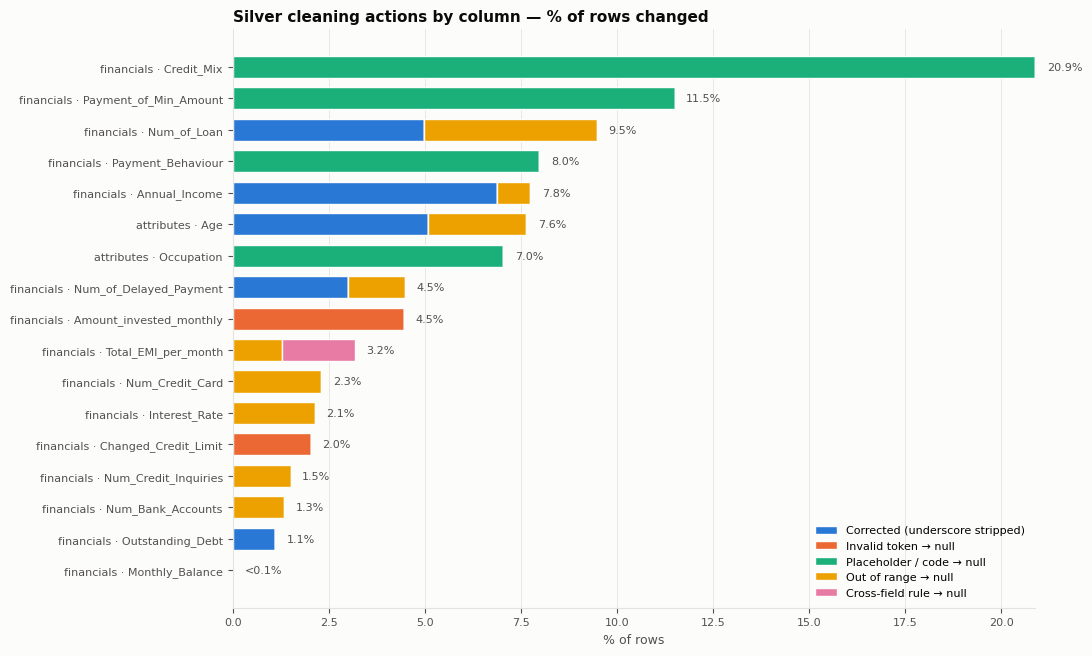

In [19]:
import matplotlib.pyplot as plt

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9})

SERIES.append("#e87ba4")   # 5th categorical slot (validated order)
actions = {"trailing_underscore_corrected": "Corrected (underscore stripped)",
           "invalid_token_to_null": "Invalid token → null",
           "placeholder_to_null": "Placeholder / code → null",
           "out_of_range_to_null": "Out of range → null",
           "exceeds_monthly_salary_to_null": "Cross-field rule → null"}
a = cleaning_audit[cleaning_audit["action"].isin(actions)]
pv = a.pivot_table(index=["table", "column"], columns="action", values="pct", aggfunc="sum").fillna(0)
pv = pv.reindex(columns=[k for k in actions if k in pv.columns])
pv = pv.loc[pv.sum(axis=1).sort_values().index]
names = [f"{t.replace('features_', '')} · {c}" for t, c in pv.index]

fig, ax = plt.subplots(figsize=(11, 0.32 * len(pv) + 1.2))
left = np.zeros(len(pv))
for color, k in zip(SERIES, pv.columns):
    ax.barh(names, pv[k], left=left, color=color, label=actions[k], height=0.7, edgecolor=SURFACE, linewidth=1)
    left += pv[k].values
for y, v in enumerate(pv.sum(axis=1)):
    ax.text(v + 0.3, y, f"{v:.1f}%" if v >= 0.1 else "<0.1%", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("% of rows")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Silver cleaning actions by column — % of rows changed")
fig.tight_layout()
os.makedirs(os.path.join(REPORT_DIR, "charts"), exist_ok=True)
fig.savefig(os.path.join(REPORT_DIR, "charts", "silver_cleaning_actions.png"), dpi=130, bbox_inches="tight")
plt.show()

In [20]:
# Example Silver rows
read_silver("features_financials").orderBy("_source_row_num").limit(3).toPandas().T

,0,1,2
Customer_ID,CUS_0x1000,CUS_0x1009,CUS_0x100b
Annual_Income,30625.94,52312.68,113781.39
Annual_Income_invalid,False,False,False
Monthly_Inhand_Salary,2706.161667,4250.39,9549.7825
Num_Bank_Accounts,6,6,1
Num_Bank_Accounts_invalid,False,False,False
Num_Credit_Card,5,5,4
Num_Credit_Card_invalid,False,False,False
Interest_Rate,27,17,1
Interest_Rate_invalid,False,False,False


### Summary

- **05:** schema contract enforced; PII not loaded; critical failures quarantined (see counts above); non-critical cast violations passed to cleaning.
- **06:** rule report before and after cleaning; after cleaning there is no FAIL — remaining WARNs are the accepted nulls (placeholders, `NM`, empty `Type_of_Loan` text) and the clickstream coverage gap.
- **07:** corrections and nulls applied per column with flags; every action counted; rows reconcile Bronze → Silver.
- **09:** `credit_history_age_months`, `type_of_loan_list`, `num_loan_types` added with unit tests; original text kept.
- **08:** below — the finished Silver compared against the Bronze baseline.

---

## Step 08 — Post-cleaning EDA: Silver vs Bronze baseline

Silver is profiled with **the same function and statistics as Bronze** (`bronze.profile_column`, step 04) and compared against the saved Bronze baseline (`datamart/bronze/_eda/`). Every material change must be explained by a cleaning decision; anything unexplained is marked **INVESTIGATE** and fails the step.

| Check | Measure | Tolerance (material if exceeded) |
|---|---|---|
| Row loss | Silver vs Bronze rows, per table and per snapshot | 0% |
| Duplicates | full-row duplicates | no increase |
| NULL % | Silver − Bronze, percentage points | 1.0 pp |
| Location | median change | 5% |
| Distribution | PSI (population stability index) on 10 Bronze-decile bins; < 0.1 stable, 0.1–0.25 moderate, > 0.25 large | 0.10 |
| Categories | largest change in the share of a **valid** category (placeholders excluded) | 2.0 pp |
| Outliers | IQR outlier count | reported, explained by range nulling |

Silver is read back from Parquet, so this checks exactly what Gold will receive.

In [21]:
SILVER_EDA_DIR = os.path.join(SILVER_DIR, "_eda")
SILVER_CHART_DIR = os.path.join(SILVER_EDA_DIR, "charts")
BRONZE_EDA_DIR = os.path.join(PROJECT_DIR, "datamart", "bronze", "_eda")
os.makedirs(SILVER_CHART_DIR, exist_ok=True)

TOL_08 = {"row_loss_pct": 0.0, "null_pct_change_pp": 1.0, "median_change_pct": 5.0, "psi": 0.10,
          "category_shift_pp": 2.0}
PSI_BINS = 10

bronze_raw = bronze.load_raw(spark)                                   # Bronze business columns as strings
silver_pd = {t: read_silver(t).drop("_silver_batch_id", "_silver_ts").toPandas() for t in TABLES}
bronze_baseline = pd.read_csv(os.path.join(BRONZE_EDA_DIR, "bronze_profile_baseline.csv"))
bronze_parts = pd.read_csv(os.path.join(BRONZE_EDA_DIR, "bronze_partition_counts.csv"), dtype={"snapshot_date": str})


def to_profile_strings(s):
    # Silver typed values -> strings, so the Bronze profiling function measures them identically
    return pd.Series([None if v is None or (isinstance(v, float) and np.isnan(v)) else str(v) for v in s],
                     index=s.index, dtype=object)


common = {t: [c for c in bronze_raw[t].columns if c in silver_pd[t].columns] for t in TABLES}
silver_profile = pd.DataFrame([bronze.profile_column(t, c, to_profile_strings(silver_pd[t][c]))
                               for t in TABLES for c in common[t]])
silver_profile["table_duplicate_rows"] = silver_profile["table"].map(
    {t: int(silver_pd[t][common[t]].astype(str).duplicated().sum()) for t in TABLES})
silver_profile.to_csv(os.path.join(SILVER_EDA_DIR, "silver_profile_baseline.csv"), index=False)
print(f"Profiled {len(silver_profile)} Silver columns with the Bronze profiling function")

Profiled 59 Silver columns with the Bronze profiling function


### Row loss and duplicates

In [22]:
silver_parts = pd.concat([
    silver_pd[t].assign(snapshot_date=silver_pd[t]["snapshot_date"].astype(str)).groupby("snapshot_date").size()
    .rename("silver_rows").reset_index().assign(table=t) for t in TABLES])
parts = bronze_parts.rename(columns={"rows": "bronze_rows"}).merge(silver_parts, on=["table", "snapshot_date"], how="outer").fillna(0)
parts["lost"] = parts["bronze_rows"] - parts["silver_rows"]

dups_b = bronze_baseline.groupby("table")["table_duplicate_rows"].first()
dups_s = silver_profile.groupby("table")["table_duplicate_rows"].first()
row_loss = (parts.groupby("table")
            .agg(bronze_rows=("bronze_rows", "sum"), silver_rows=("silver_rows", "sum"),
                 partitions=("snapshot_date", "count"), partitions_with_loss=("lost", lambda s: int((s != 0).sum())))
            .reindex(TABLES).reset_index())
row_loss["row_loss_pct"] = (row_loss["bronze_rows"] - row_loss["silver_rows"]) / row_loss["bronze_rows"] * 100
row_loss["duplicates_bronze"] = row_loss["table"].map(dups_b)
row_loss["duplicates_silver"] = row_loss["table"].map(dups_s)
row_loss["status"] = np.where((row_loss["row_loss_pct"] <= TOL_08["row_loss_pct"])
                              & (row_loss["duplicates_silver"] <= row_loss["duplicates_bronze"]), "PASS", "INVESTIGATE")
STATUS_STYLE["EXPLAINED"] = ("ℹ EXPLAINED", "#e3eefb")
STATUS_STYLE["INVESTIGATE"] = ("✖ INVESTIGATE", "#f8dede")
styled(row_loss).format({"bronze_rows": "{:,.0f}", "silver_rows": "{:,.0f}", "row_loss_pct": "{:.2f}%"})

table,bronze_rows,silver_rows,partitions,partitions_with_loss,row_loss_pct,duplicates_bronze,duplicates_silver,status
lms_loan_daily,"137,500","137,500",35,0,0.00%,0,0,✔ PASS
feature_clickstream,"215,376","215,376",24,0,0.00%,0,0,✔ PASS
features_attributes,"12,500","12,500",25,0,0.00%,0,0,✔ PASS
features_financials,"12,500","12,500",25,0,0.00%,0,0,✔ PASS


### Column comparison — Bronze baseline vs Silver

In [23]:
def numeric_values(s):
    v = s.dropna().astype(str)
    return pd.to_numeric(v[v.str.fullmatch(bronze.NUMERIC_RE)])


def psi(expected, actual, bins=PSI_BINS):
    if len(expected) == 0 or len(actual) == 0:
        return np.nan
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 2:                                     # constant column
        return 0.0 if (actual == edges[0]).all() else np.inf
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


def category_shift(t, c):
    # Largest change in the share of a VALID category (shares among valid values only)
    valid = VALID_CATEGORIES[(t, c)]
    b = bronze_raw[t][c][bronze_raw[t][c].isin(valid)].value_counts(normalize=True)
    s = silver_pd[t][c].dropna().value_counts(normalize=True)
    return float((s.reindex(valid).fillna(0) - b.reindex(valid).fillna(0)).abs().max() * 100)


stats = ["inferred_type", "null_pct", "distinct", "min", "p01", "p50", "p99", "max", "mean", "std", "skew", "iqr_outliers"]
cmp = bronze_baseline[["table", "column", *stats]].merge(silver_profile[["table", "column", *stats]],
                                                         on=["table", "column"], suffixes=("_bronze", "_silver"))
num = lambda s: pd.to_numeric(s, errors="coerce")
cmp["null_pct_change_pp"] = cmp["null_pct_silver"] - cmp["null_pct_bronze"]
cmp["median_change_pct"] = np.where(num(cmp["p50_bronze"]).abs() > 0,
                                    (num(cmp["p50_silver"]) - num(cmp["p50_bronze"])) / num(cmp["p50_bronze"]).abs() * 100,
                                    np.nan)
cmp["psi"] = [psi(numeric_values(bronze_raw[t][c]), numeric_values(silver_pd[t][c]))
              if it == "numeric" else np.nan
              for t, c, it in zip(cmp["table"], cmp["column"], cmp["inferred_type_bronze"])]
cmp["category_shift_pp"] = [category_shift(t, c) if (t, c) in VALID_CATEGORIES else np.nan
                            for t, c in zip(cmp["table"], cmp["column"])]

# Explanations: the cleaning actions and decisions recorded for each column
audit_text = (cleaning_audit.assign(txt=lambda d: d["action"] + " " + d["pct"].round(2).astype(str) + "%")
              .groupby(["table", "column"])["txt"].agg("; ".join))
decision_text = (register.groupby(["table", "column"])
                 .apply(lambda g: ", ".join(f"{i} {d}" for i, d in zip(g["issue_id"], g["decision"])), include_groups=False))

def assess(r):
    reasons = []
    if abs(r["null_pct_change_pp"]) > TOL_08["null_pct_change_pp"]:
        reasons.append(f"null % {r['null_pct_bronze']:.2f} -> {r['null_pct_silver']:.2f}")
    if pd.notna(r["median_change_pct"]) and abs(r["median_change_pct"]) > TOL_08["median_change_pct"]:
        reasons.append(f"median {r['median_change_pct']:+.1f}%")
    if pd.notna(r["psi"]) and r["psi"] > TOL_08["psi"]:
        reasons.append(f"PSI {r['psi']:.3f}")
    if pd.notna(r["category_shift_pp"]) and r["category_shift_pp"] > TOL_08["category_shift_pp"]:
        reasons.append(f"category share shift {r['category_shift_pp']:.2f} pp")
    key = (r["table"], r["column"])
    explanation = "; ".join(x for x in [audit_text.get(key, ""), decision_text.get(key, "")] if x)
    status = "PASS" if not reasons else ("EXPLAINED" if key in audit_text.index else "INVESTIGATE")
    return pd.Series(dict(material_change="; ".join(reasons), status=status,
                          explanation=explanation if reasons else ""))

cmp = pd.concat([cmp, cmp.apply(assess, axis=1)], axis=1)
cmp.to_csv(os.path.join(SILVER_EDA_DIR, "bronze_vs_silver_comparison.csv"), index=False)
print("Columns:", cmp["status"].value_counts().to_dict())

view_cols = ["table", "column", "null_pct_bronze", "null_pct_silver", "p50_bronze", "p50_silver",
             "max_bronze", "max_silver", "iqr_outliers_bronze", "iqr_outliers_silver", "psi",
             "category_shift_pp", "status", "material_change"]
fmt = lambda v: f"{v:,.2f}" if isinstance(v, (int, float, np.integer, np.floating)) and pd.notna(v) else ("" if pd.isna(v) else v)
styled(cmp[view_cols]).format({c: fmt for c in view_cols if c not in ("table", "column", "status", "material_change")})

Columns: {'PASS': 45, 'EXPLAINED': 14}


table,column,null_pct_bronze,null_pct_silver,p50_bronze,p50_silver,max_bronze,max_silver,iqr_outliers_bronze,iqr_outliers_silver,psi,category_shift_pp,status,material_change
lms_loan_daily,loan_id,0.00,0.00,,,,,,,,,✔ PASS,
lms_loan_daily,Customer_ID,0.00,0.00,,,,,,,,,✔ PASS,
lms_loan_daily,loan_start_date,0.00,0.00,,,2025-01-01,2025-01-01,,,,,✔ PASS,
lms_loan_daily,tenure,0.00,0.00,10.00,10.00,10,10.00,0.00,0.00,0.00,,✔ PASS,
lms_loan_daily,installment_num,0.00,0.00,5.00,5.00,10,10.00,0.00,0.00,0.00,,✔ PASS,
lms_loan_daily,loan_amt,0.00,0.00,"10,000.00","10,000.00",10000,"10,000.00",0.00,0.00,0.00,,✔ PASS,
lms_loan_daily,due_amt,0.00,0.00,"1,000.00","1,000.00",1000.0,"1,000.00","12,500.00","12,500.00",0.00,,✔ PASS,
lms_loan_daily,paid_amt,0.00,0.00,"1,000.00","1,000.00",4000.0,"4,000.00",277.00,277.00,0.00,,✔ PASS,
lms_loan_daily,overdue_amt,0.00,0.00,0.00,0.00,10000.0,"10,000.00","28,876.00","28,876.00",0.00,,✔ PASS,
lms_loan_daily,balance,0.00,0.00,"7,000.00","7,000.00",10000.0,"10,000.00",0.00,0.00,0.00,,✔ PASS,


**How to read this table:** the medians (`p50`) and PSI show whether cleaning distorted the *typical* values; `max` and the IQR outlier counts show the impossible tail being removed; `null %` shows the price paid (values set to null). A column is **EXPLAINED** when its material change matches a recorded cleaning action.

### Charts — Bronze vs Silver

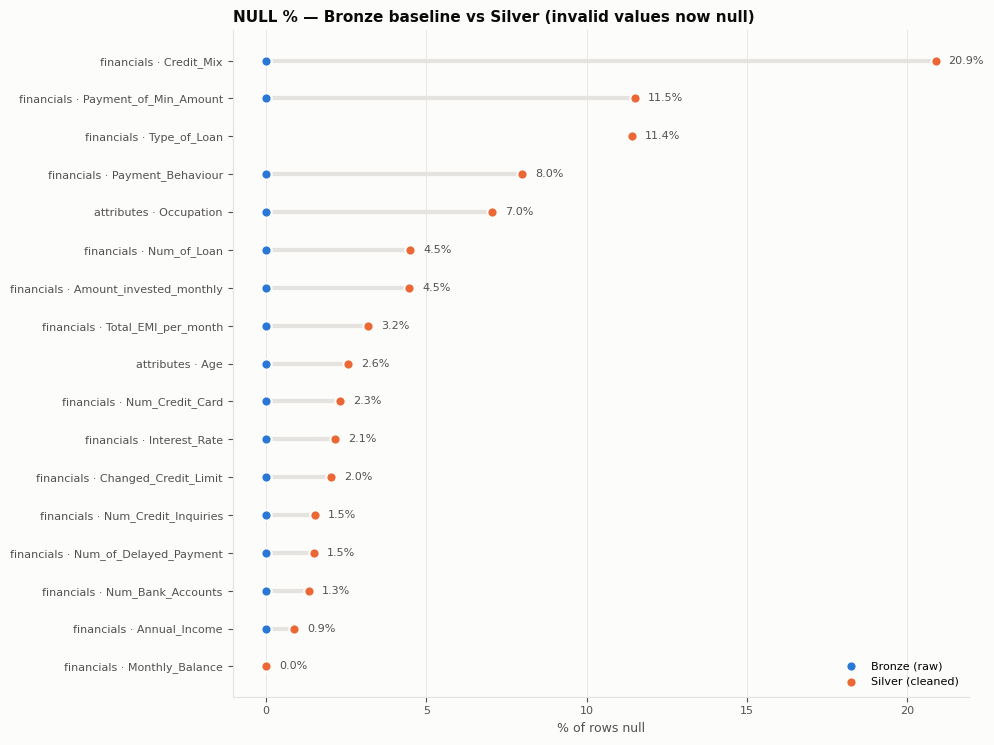

In [24]:
# 1. NULL % before and after cleaning (dumbbell: Bronze -> Silver)
d = cmp[(cmp["null_pct_bronze"] > 0) | (cmp["null_pct_silver"] > 0)].copy()
d = d.sort_values("null_pct_silver")
d["name"] = d["table"].str.replace("features_", "") + " · " + d["column"]
fig, ax = plt.subplots(figsize=(10, 0.36 * len(d) + 1.4))
y = np.arange(len(d))
ax.hlines(y, d["null_pct_bronze"], d["null_pct_silver"], color=GRID, linewidth=3, zorder=1)
ax.scatter(d["null_pct_bronze"], y, color=SERIES[0], s=55, zorder=2, label="Bronze (raw)", edgecolor=SURFACE, linewidth=1.5)
ax.scatter(d["null_pct_silver"], y, color=SERIES[1], s=55, zorder=3, label="Silver (cleaned)", edgecolor=SURFACE, linewidth=1.5)
for yi, v in zip(y, d["null_pct_silver"]):
    ax.text(v + 0.4, yi, f"{v:.1f}%", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, d["name"])
ax.set_xlabel("% of rows null")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("NULL % — Bronze baseline vs Silver (invalid values now null)")
fig.tight_layout()
fig.savefig(os.path.join(SILVER_CHART_DIR, "08_1_null_pct_bronze_vs_silver.png"), dpi=130, bbox_inches="tight")
plt.show()

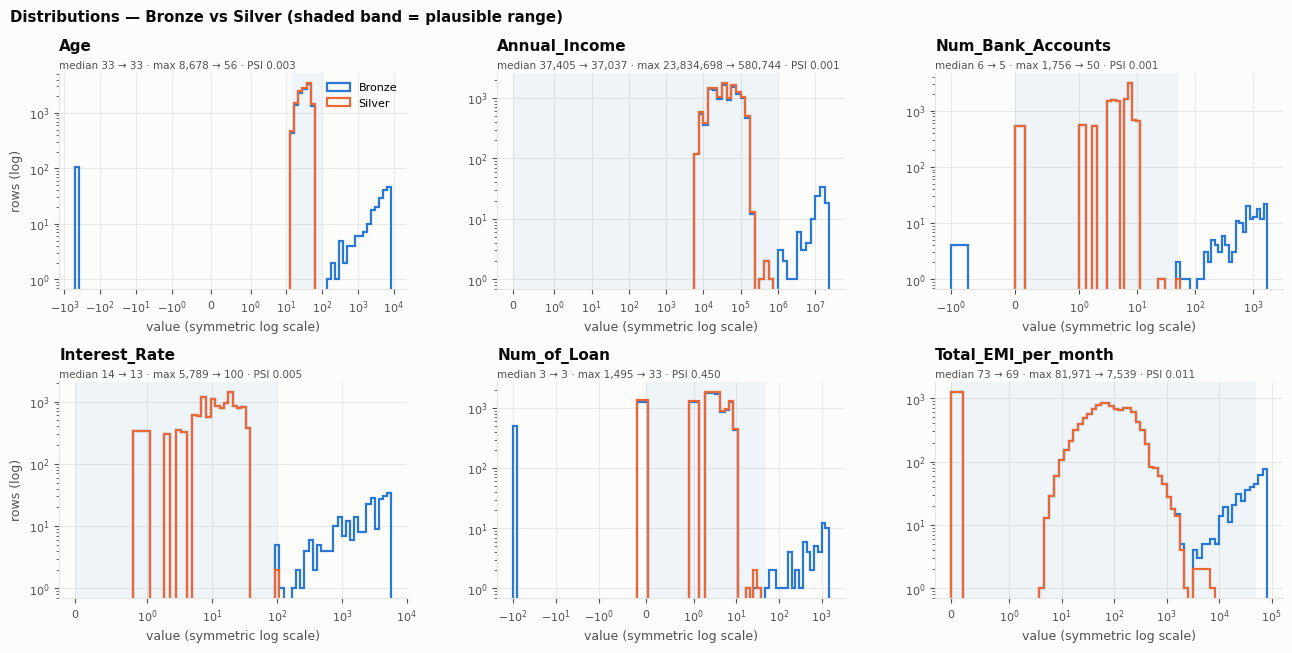

In [25]:
# 2. Distributions: Bronze (all parseable values) vs Silver — the impossible tail is gone, the body is unchanged
fields = [("features_attributes", "Age"), ("features_financials", "Annual_Income"),
          ("features_financials", "Num_Bank_Accounts"), ("features_financials", "Interest_Rate"),
          ("features_financials", "Num_of_Loan"), ("features_financials", "Total_EMI_per_month")]
to_sym = lambda v: np.sign(v) * np.log10(1 + np.abs(v))
from_sym = lambda v: np.sign(v) * (10 ** np.abs(v) - 1)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for ax, (t, c) in zip(axes.flat, fields):
    b, s = numeric_values(bronze_raw[t][c]), numeric_values(silver_pd[t][c])
    lo, hi = SILVER_RANGE_RULES[(t, c)]
    ax.axvspan(lo, hi, color=SERIES[0], alpha=0.06, lw=0)
    bins = from_sym(np.linspace(to_sym(min(b.min(), 0)), to_sym(b.max()), 60))
    ax.hist(b, bins=bins, histtype="step", color=SERIES[0], linewidth=1.6, label="Bronze")
    ax.hist(s, bins=bins, histtype="step", color=SERIES[1], linewidth=1.6, label="Silver")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("log")
    r = cmp.set_index(["table", "column"]).loc[(t, c)]
    ax.set_title(c, pad=16)
    ax.text(0, 1.01, f"median {float(r['p50_bronze']):,.0f} → {float(r['p50_silver']):,.0f} · "
                     f"max {float(r['max_bronze']):,.0f} → {float(r['max_silver']):,.0f} · PSI {r['psi']:.3f}",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=7.5, color=INK_2)
    ax.set_xlabel("value (symmetric log scale)")
for ax in axes[:, 0]:
    ax.set_ylabel("rows (log)")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Distributions — Bronze vs Silver (shaded band = plausible range)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(SILVER_CHART_DIR, "08_2_distributions_bronze_vs_silver.png"), dpi=130, bbox_inches="tight")
plt.show()

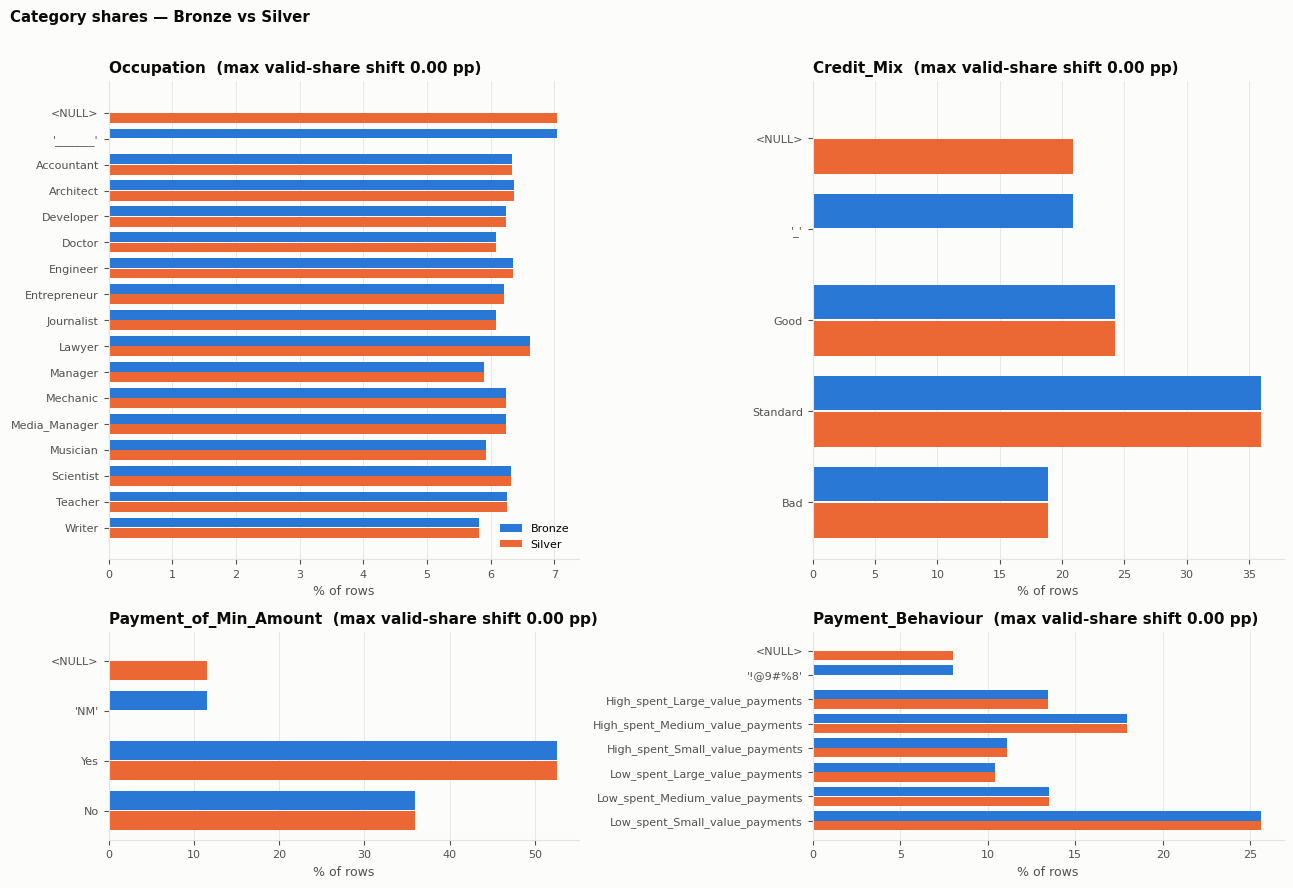

In [26]:
# 3. Category shares: placeholders move to <NULL>, the valid categories keep their shares
cats = list(VALID_CATEGORIES)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), gridspec_kw={"height_ratios": [2.3, 1]})
for ax, (t, c) in zip(axes.flat, cats):
    b = bronze_raw[t][c].fillna("<NULL>").value_counts(normalize=True) * 100
    s = silver_pd[t][c].fillna("<NULL>").value_counts(normalize=True) * 100
    order = VALID_CATEGORIES[(t, c)][::-1] + [v for v in b.index if v not in VALID_CATEGORIES[(t, c)]] + ["<NULL>"]
    order = list(dict.fromkeys(order))
    labels = [v if v in VALID_CATEGORIES[(t, c)] or v == "<NULL>" else f"'{v}'" for v in order]
    yy = np.arange(len(order))
    ax.barh(yy + 0.2, b.reindex(order).fillna(0), height=0.38, color=SERIES[0], label="Bronze")
    ax.barh(yy - 0.2, s.reindex(order).fillna(0), height=0.38, color=SERIES[1], label="Silver")
    ax.set_yticks(yy, labels)
    ax.set_title(f"{c}  (max valid-share shift {category_shift(t, c):.2f} pp)")
    ax.set_xlabel("% of rows")
    ax.grid(axis="y", visible=False)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Category shares — Bronze vs Silver", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(os.path.join(SILVER_CHART_DIR, "08_3_categories_bronze_vs_silver.png"), dpi=130, bbox_inches="tight")
plt.show()

### New Silver columns (step 07 flags, step 09 parsed fields)

In [27]:
f_pd = silver_pd["features_financials"]
new_cols = pd.DataFrame([
    dict(column="credit_history_age_months", null_pct=f_pd["credit_history_age_months"].isna().mean() * 100,
         min=f_pd["credit_history_age_months"].min(), p50=f_pd["credit_history_age_months"].median(),
         max=f_pd["credit_history_age_months"].max(), note="parsed from Credit_History_Age"),
    dict(column="num_loan_types", null_pct=f_pd["num_loan_types"].isna().mean() * 100,
         min=f_pd["num_loan_types"].min(), p50=f_pd["num_loan_types"].median(), max=f_pd["num_loan_types"].max(),
         note=f"{(f_pd['num_loan_types'] == 0).mean() * 100:.1f}% have no loans"),
])

# Flag rates must equal the share of values cleaning set to null (consistency check)
nulled = (cleaning_audit[cleaning_audit["action"].isin(["invalid_token_to_null", "out_of_range_to_null", "placeholder_to_null",
                                                        "exceeds_monthly_salary_to_null"])]
          .groupby(["table", "column"])["pct"].sum())
flags = pd.DataFrame([dict(table=t, column=c, flag=f"{c}_invalid",
                           flag_rate_pct=silver_pd[t][f"{c}_invalid"].mean() * 100,
                           nulled_by_cleaning_pct=nulled.get((t, c), 0.0))
                      for t, cols in CLEANING_FLAG_COLUMNS.items() for c in cols])
assert np.allclose(flags["flag_rate_pct"], flags["nulled_by_cleaning_pct"]), flags
display(new_cols.style.hide(axis="index").format({"null_pct": "{:.2f}%", "p50": "{:.0f}"}))
flags.style.hide(axis="index").format({"flag_rate_pct": "{:.2f}%", "nulled_by_cleaning_pct": "{:.2f}%"})

column,null_pct,min,p50,max,note
credit_history_age_months,0.00%,8,222,404,parsed from Credit_History_Age
num_loan_types,0.00%,0,3,9,11.4% have no loans


table,column,flag,flag_rate_pct,nulled_by_cleaning_pct
features_attributes,Age,Age_invalid,2.55%,2.55%
features_attributes,Occupation,Occupation_invalid,7.04%,7.04%
features_financials,Annual_Income,Annual_Income_invalid,0.88%,0.88%
features_financials,Num_Bank_Accounts,Num_Bank_Accounts_invalid,1.34%,1.34%
features_financials,Num_Credit_Card,Num_Credit_Card_invalid,2.31%,2.31%
features_financials,Interest_Rate,Interest_Rate_invalid,2.14%,2.14%
features_financials,Num_of_Loan,Num_of_Loan_invalid,4.50%,4.50%
features_financials,Num_of_Delayed_Payment,Num_of_Delayed_Payment_invalid,1.49%,1.49%
features_financials,Changed_Credit_Limit,Changed_Credit_Limit_invalid,2.03%,2.03%
features_financials,Num_Credit_Inquiries,Num_Credit_Inquiries_invalid,1.51%,1.51%


### Action log and acceptance

In [28]:
log_rows = []
for _, r in cmp[cmp["status"] != "PASS"].iterrows():
    for reason in r["material_change"].split("; "):
        log_rows.append(dict(table=r["table"], column=r["column"], change=reason, status=r["status"],
                             explanation=r["explanation"],
                             action="accept — expected result of the recorded cleaning decision"
                                    if r["status"] == "EXPLAINED" else "investigate before Gold"))
for _, r in row_loss[row_loss["status"] != "PASS"].iterrows():
    log_rows.append(dict(table=r["table"], column="*", change=f"row loss {r['row_loss_pct']:.2f}%",
                         status="INVESTIGATE", explanation="", action="investigate before Gold"))
action_log = pd.DataFrame(log_rows, columns=["table", "column", "change", "status", "explanation", "action"])
action_log.to_csv(os.path.join(SILVER_EDA_DIR, "silver_vs_bronze_action_log.csv"), index=False)

assert (row_loss["status"] == "PASS").all(), "unexpected row loss or new duplicates"
assert (cmp["status"] != "INVESTIGATE").all(), cmp.loc[cmp["status"] == "INVESTIGATE", ["table", "column", "material_change"]]
print(f"Step 08 accepted: no row loss, no new duplicates, {(cmp['status'] == 'EXPLAINED').sum()} material changes "
      f"all explained by cleaning decisions, {(cmp['status'] == 'PASS').sum()} columns unchanged within tolerance")
styled(action_log)

Step 08 accepted: no row loss, no new duplicates, 14 material changes all explained by cleaning decisions, 45 columns unchanged within tolerance


table,column,change,status,explanation,action
features_attributes,Age,null % 0.00 -> 2.55,ℹ EXPLAINED,"trailing_underscore_corrected 5.1%; out_of_range_to_null 2.55%; BRZ-002 correct, BRZ-013 transform",accept — expected result of the recorded cleaning decision
features_attributes,Occupation,null % 0.00 -> 7.04,ℹ EXPLAINED,placeholder_to_null 7.04%; BRZ-004 transform,accept — expected result of the recorded cleaning decision
features_financials,Num_Bank_Accounts,null % 0.00 -> 1.34,ℹ EXPLAINED,out_of_range_to_null 1.34%; BRZ-022 transform,accept — expected result of the recorded cleaning decision
features_financials,Num_Bank_Accounts,median -16.7%,ℹ EXPLAINED,out_of_range_to_null 1.34%; BRZ-022 transform,accept — expected result of the recorded cleaning decision
features_financials,Num_Credit_Card,null % 0.00 -> 2.31,ℹ EXPLAINED,out_of_range_to_null 2.31%; BRZ-023 transform,accept — expected result of the recorded cleaning decision
features_financials,Interest_Rate,null % 0.00 -> 2.14,ℹ EXPLAINED,out_of_range_to_null 2.14%; BRZ-020 transform,accept — expected result of the recorded cleaning decision
features_financials,Interest_Rate,median -7.1%,ℹ EXPLAINED,out_of_range_to_null 2.14%; BRZ-020 transform,accept — expected result of the recorded cleaning decision
features_financials,Num_of_Loan,null % 0.00 -> 4.50,ℹ EXPLAINED,"trailing_underscore_corrected 4.98%; out_of_range_to_null 4.5%; BRZ-027 correct, BRZ-028 transform",accept — expected result of the recorded cleaning decision
features_financials,Num_of_Loan,PSI 0.450,ℹ EXPLAINED,"trailing_underscore_corrected 4.98%; out_of_range_to_null 4.5%; BRZ-027 correct, BRZ-028 transform",accept — expected result of the recorded cleaning decision
features_financials,Num_of_Delayed_Payment,null % 0.00 -> 1.49,ℹ EXPLAINED,"trailing_underscore_corrected 2.99%; out_of_range_to_null 1.49%; BRZ-025 correct, BRZ-026 transform",accept — expected result of the recorded cleaning decision


### Step 08 summary

- **No row loss and no new duplicates** — every Bronze row is in Silver (nothing was quarantined).
- **Typical values unchanged:** medians and PSI stay within tolerance for the numeric columns, so cleaning removed the impossible tail without distorting the body of the distributions.
- **Material changes are all explained:** higher null % where invalid values, placeholders and `NM` were set to null; much lower maxima and fewer IQR outliers where out-of-range values were removed. Each is linked to its cleaning action and Bronze issue in the action log.
- **Valid categories keep their shares** — only placeholders moved to null.

**Gate 1 check (raw data reproducible; Bronze EDA documented; Silver cleaning validated against raw baseline):** Bronze reruns are idempotent (step 02), the Bronze EDA and issue register are documented (step 04), and Silver is validated against the raw baseline here with no unexplained change.